# Word2vec trainieren und Wortbeziehungen untersuchen - Übung

**Geschäftsfrage:** Wie können wir nützliche Beziehungen zwischen Wörtern aus E-Mails lernen, bevor wir einen Spam-Detektor entwickeln?

Wir werden word2vec trainieren, Wörter auswählen, deren Beziehungen wir untersuchen möchten, und eine Karte ihrer gelernten Beziehungen zeichnen. Seite 17 von *Slides_MSC_Data_Science_Week_08_EN.pdf* zeigt ein Beispiel; deine Karte kann andere Wörter verwenden.

## Was du lernen wirst

- Erklären, wie word2vec aus Wörtern lernt, die nahe beieinander vorkommen.
- Ein Modell trainieren, das jedes Wort als eine Liste von Zahlen darstellt, die als **Wortvektor** bezeichnet wird.
- Eine Wortkarte zeichnen und überprüfen, ob sie mit der Kosinus-Ähnlichkeit übereinstimmt.
- Erklären, was die Darstellung über die Spam-Erkennung aussagen kann und was nicht.

## Die E-Mail-Daten

Wir verwenden **`email_spam_text.csv.gz\`**, eine Datei, die 30'000 E-Mails aus dem ursprünglichen Experiment enthält. Pandas kann diese komprimierte Datei direkt öffnen. In Codespaces ist kein zusätzlicher Download oder Upload erforderlich.

Die E-Mails sind bereits in drei Gruppen aufgeteilt:

- **Training: 18'000 E-Mails.** Word2vec lernt aus den Wörtern dieser E-Mails.
- **Validierung: 6'000 E-Mails.** Diese werden für spätere Modellentscheidungen zurückbehalten.
- **Test: 6'000 E-Mails.** Diese werden für die abschliessende Überprüfung eines Spam-Detektors zurückbehalten.

**Word2vec verwendet die Spam-Labels nicht.** Es lernt aus benachbarten Wörtern und nicht daraus, ob eine E-Mail Spam ist. In dieser Übung werden Wortvektoren trainiert; ein Spam-Detektor wird noch nicht trainiert.

Die Datei `email_spam.csv` ist anders: Sie enthält Häufigkeitswerte und andere numerische Merkmale, nicht die ursprünglichen Wörter. Wir können sie deshalb nicht verwenden, um word2vec zu trainieren.

Alle Wortvektoren stammen aus dem Modell, das wir in diesem Notebook trainieren. Wir laden keine separate Datei mit gespeicherten Wortvektoren.

Die bereitgestellten E-Mail-Texte sind für die vorgesehene Zielgruppe des Kurses freigegeben. Zeige keine privaten Nachrichten an und gib die Daten nicht ausserhalb der erlaubten Verwendung weiter. Weitere Informationen findest du in den [Hinweisen zu den Daten]\(../../../00_Data/nlp_data_readme.md).

**Deine Aufgaben:** Vervollständige die drei mit `# TODO` markierten \`None\`-Werte und beantworte anschliessend die Fragen. Führe die Zellen von oben nach unten aus. Beginne mit dem [Konzept-Notebook]\(text_embeddings_concept.ipynb), wenn du eine Auffrischung zu Wortvektoren benötigst.

## 1. Bibliotheken laden und Einstellungen festlegen

Wir trainieren unser eigenes Modell mit PyTorch auf der CPU. Wir laden kein vortrainiertes Modell herunter.

Jedes Wort wird durch **100 Zahlen** dargestellt. Beim Training werden die Trainings-E-Mails **fünfmal vollständig durchlaufen**. Ein solcher Durchlauf wird als **Epoche** bezeichnet.

Der **Zufalls-Seed** sorgt dafür, dass zufällige Entscheidungen wiederholbar sind, solange die Software und die Daten gleich bleiben. Wir verwenden wie im ursprünglichen Experiment den Seed 7. Unterschiedliche Softwareversionen können trotzdem zu unterschiedlichen Ergebnissen führen.

Behalte `MAX_MESSAGES = 30_000` bei, damit die vorgegebenen Datengruppen unverändert bleiben. Du kannst mit weniger Epochen experimentieren, um den Code zu erkunden, aber dadurch verändert sich das Experiment. Ein Live-Diagramm zeigt den Fortschritt während des Trainings an.

In [1]:
from pathlib import Path
from collections import Counter
from importlib.metadata import version
import os
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

DATA_ROOT = Path('../../../00_Data').resolve()
RAW_EMAIL_PATH = Path(os.environ.get('SPAM_DATA_PATH', str(DATA_ROOT / 'email_spam_text.csv.gz'))).expanduser()
SEED = 7
MAX_MESSAGES = 30_000
VECTOR_SIZE = 100
EPOCHS = 5
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
display(pd.Series({name: version(name) for name in ['numpy', 'torch', 'scikit-learn']},
                  name='Installed version'))

numpy              1.26.4
torch           2.2.2+cpu
scikit-learn        1.6.1
Name: Installed version, dtype: object

## 2. Die E-Mails laden

Wir verwenden den Code zum Einlesen der Daten aus dem Material zu neuronalen Netzwerken erneut. Er behält die vorgegebenen Trainings-, Validierungs- und Testgruppen in ihrer ursprünglichen Reihenfolge bei.

Für das Training zerlegen wir die Betreffzeilen und Inhalte der E-Mails in kleine Einheiten, sogenannte **Tokens**. Hier sind das kleingeschriebene Wörter, verkürzte Wortformen wie `don't` oder Ziffernfolgen.

Wir zeigen nur Anzahlen an, keine echten Nachrichten. Ausserdem halten wir die E-Mails getrennt: Ein Wort am Ende einer E-Mail wird niemals mit einem Wort aus der nächsten E-Mail gepaart.

In [2]:
if not RAW_EMAIL_PATH.is_file():
    raise FileNotFoundError(
        'Set RAW_EMAIL_PATH or SPAM_DATA_PATH to the authorised raw message/label CSV. '
        'The supplied default is 00_Data/email_spam_text.csv.gz.')
if not {'message', 'label'}.issubset(pd.read_csv(RAW_EMAIL_PATH, nrows=0).columns):
    raise ValueError('Word2vec needs raw message and label columns, not the feature-only email CSV.')
sys.path.insert(0, str(DATA_ROOT.parent / '08_Neural_Networks/HS2026'))
from enron_data import load_email_splits

train, validation, test = load_email_splits(RAW_EMAIL_PATH, max_messages=MAX_MESSAGES, seed=SEED)
TOKEN_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+")
training_text = train.subject.fillna('') + '\n' + train.body.fillna('')
training_tokens = training_text.map(lambda text: TOKEN_PATTERN.findall(text.casefold())).tolist()
display(pd.Series({'train emails': len(train), 'validation emails': len(validation),
                   'test emails': len(test), 'training tokens': sum(map(len, training_tokens))},
                  name='Data summary'))

train emails           18000
validation emails       6000
test emails             6000
training tokens      4821028
Name: Data summary, dtype: int64

## 3. Wörter finden, die nahe beieinander vorkommen

Betrachte die erfundene Wortfolge **"claim your prize"** („Fordere deinen Preis an“). Daraus entstehen Wortpaare wie `claim / prize`. Anhand vieler E-Mails lernt das Modell aus solchen wiederkehrenden Mustern.

Das Wort, von dem wir ausgehen, wird als **Zentrumswort** bezeichnet. Ein Wort in seiner Nähe wird als **Kontextwort** bezeichnet.

Die Liste der Wörter, die das Modell kennt, wird als **Vokabular** bezeichnet. Wir behalten Wörter, die mindestens fünfmal vorkommen, und begrenzen das Vokabular auf maximal 30'000 unterschiedliche Wörter. Sehr häufige Wörter werden manchmal übersprungen, damit sie das Training nicht dominieren.

Der bereitgestellte Code erstellt Wortpaare aus kurzen Textabschnitten und betrachtet dabei bis zu fünf Positionen nach links und rechts. Du musst diesen Code nicht verändern. Die Anzahl der Wörter im Vokabular reicht für unsere Untersuchung aus; wir geben nicht die vollständige Wortliste aus.

In [3]:
word_counts = Counter(word for document in training_tokens for word in document)
vocabulary = sorted(
    (word for word, count in word_counts.items() if count >= 5),
    key=lambda word: (-word_counts[word], word),
)[:30_000]
if len(vocabulary) < 2:
    raise ValueError('Training text needs at least two words with frequency >= 5.')
word_to_index = {word: index for index, word in enumerate(vocabulary)}
counts = np.array([word_counts[word] for word in vocabulary], dtype=np.float64)
frequencies = counts / counts.sum()
keep_probability = np.minimum(1., np.sqrt(1e-3 / frequencies) + 1e-3 / frequencies)
noise_distribution = torch.tensor(counts ** 0.75 / (counts ** 0.75).sum(), dtype=torch.float32)
training_ids = [
    np.array([word_to_index[word] for word in document if word in word_to_index], dtype=np.int64)
    for document in training_tokens
]
print('Training vocabulary size:', len(vocabulary))

Training vocabulary size: 30000


In [4]:
def pair_batches(documents, keep_probability, rng, batch_size=4096):
    pending, pending_count = [], 0
    for ids in documents:
        for start in range(0, len(ids), 100):
            span = ids[start:start + 100]
            span = span[rng.random(len(span)) < keep_probability[span]]
            pairs = []
            for distance in range(1, min(5, len(span) - 1) + 1):
                left, right = span[:-distance], span[distance:]
                pairs.extend([np.column_stack((left, right)), np.column_stack((right, left))])
            if not pairs:
                continue
            pending.append(np.concatenate(pairs))
            pending_count += len(pending[-1])
            if pending_count >= batch_size:
                combined = np.concatenate(pending)
                stop = len(combined) // batch_size * batch_size
                for offset in range(0, stop, batch_size):
                    yield combined[offset:offset + batch_size]
                pending = [combined[stop:]]
                pending_count = len(combined) - stop
    if pending_count:
        yield np.concatenate(pending)

## 4. Dem Modell eine Lernaufgabe geben

**Skip-gram** ist eine Methode, um word2vec mithilfe eines Zentrumswortes und benachbarter Wörter zu trainieren. Das Modell speichert zwei Tabellen mit Zahlen:

1\. Eine Tabelle für das Wort, von dem wir ausgehen.
2\. Eine Tabelle für das benachbarte Wort, mit dem wir es vergleichen.

Ein **Skalarprodukt** kombiniert die beiden Vektoren zu einem Wert (Score). Beim Training werden die Zahlen so angepasst, dass echte benachbarte Wortpaare tendenziell höhere Scores erhalten als zufällig zusammengestellte Wortpaare.

Für jedes echte Wortpaar wählen wir fünf zufällige Vergleichswörter aus. Dies wird als **Negative Sampling** bezeichnet. Es ist schneller, als jedes Wort mit dem gesamten Vokabular zu vergleichen.

Die Sigmoid-Funktion wandelt jeden Score in einen Wert zwischen null und eins um. Der **Loss (Verlustwert)** misst, wie schlecht das Modell echte Wortpaare von zufälligen Wortpaaren unterscheiden kann. Je niedriger der Loss, desto besser ist das für diese Aufgabe. Diese Scores sind **keine Spam-Wahrscheinlichkeiten**.

Die Folien verwenden Softmax, um Vorhersagen über alle möglichen benachbarten Wörter zu erklären. Unsere schnellere Trainingsmethode berechnet nicht diese vollständige Menge an Wahrscheinlichkeiten.

Die beiden folgenden `nn.Embedding`-Zeilen erstellen die Tabellen. Wir werden die erste Tabelle verwenden, um die Wortkarte zu zeichnen.

## Der Loss, den wir tatsächlich berechnen

`SkipGramNegativeSampling\` enthält **sowohl die Embedding-Tabellen als auch die Loss-Berechnung**. Der Aufruf `word2vec(centres, contexts, negatives)` führt die Methode `forward()` aus und gibt den Loss für diesen Batch zurück. Es gibt keinen separaten `.fit()`-Aufruf: Unsere Trainingsschleife berechnet den Loss, ruft `loss.backward()` zur Berechnung der Gradienten auf und verwendet `optimizer.step()`, um die Tabellen zu aktualisieren.

Für ein beobachtetes Wortpaar und fünf zufällig ausgewählte Vergleichswörter lautet die Loss-Funktion:

$$\ell = -\log\sigma(\mathbf{v}\_w^\top\mathbf{u}\_c) - \sum\_{j=1}^{5}\log\sigma(-\mathbf{v}\_w^\top\mathbf{u}\_{n_j})$$

- $w$ ist das Zentrumswort; $c$ ist ein tatsächlich beobachtetes benachbartes Wort; $n_j$ ist das Vergleichswort mit der Nummer $j$.
- $\mathbf{v}\_w$ stammt aus der Tabelle der Zentrumswörter. $\mathbf{u}\_c$ und $\mathbf{u}\_{n_j}$ stammen aus der Tabelle der Kontextwörter.
- $\mathbf{v}^\top\mathbf{u}$ ist der durch das Skalarprodukt berechnete Score, und $\sigma(z)=1/(1+e^{-z})$ ist die Sigmoid-Funktion.
- Der erste Term fördert einen **hohen Score für das beobachtete Wortpaar**. Der zweite fördert **niedrige Scores für die zufällig ausgewählten Vergleichspaare**. Zufällig ausgewählte Wörter müssen nicht unbedingt inhaltlich unabhängig voneinander sein.

Für einen Batch mit $B$ beobachteten Wortpaaren berechnen wir den Durchschnitt: $L\_{\mathrm{batch}} = \frac{1}{B}\sum\_{i=1}^{B}\ell_i$. Dies entspricht der unten stehenden Return-Anweisung: `positive` enthält die Scores der beobachteten Wortpaare; `negative` enthält die Scores der Vergleichspaare; `.sum(dim=1)` addiert die fünf Vergleichsverluste; `.mean()` berechnet den Durchschnitt über den Batch. `F.logsigmoid` berechnet den Logarithmus der Sigmoid-Funktion auf numerisch stabile Weise.

Dies entspricht der binären Kreuzentropie (Binary Cross-Entropy) mit dem Label **1 für beobachtete Wortpaare** und **0 für zufällig ausgewählte Vergleichspaare**. Die Verluste werden für die sechs Wortpaare jedes Zentrumswort-Kontext-Beispiels addiert und anschliessend über den Batch gemittelt. Wir lernen die Vektoren, aus denen diese Scores entstehen. **Spam-Labels werden nicht verwendet.**

**### Wie viele Parameter lernen wir?**

Ein Parameter ist eine einzelne Zahl, die angepasst werden kann. Bei einer Vokabulargrösse von $V$ und einer Vektorlänge von $d$ enthalten die beiden Tabellen **$2Vd$ trainierbare Parameter**. Im bereitgestellten vollständigen Trainingsdurchlauf gilt $V=30{,}000$ und $d=100$:

| Tabelle | Berechnung | Parameter |
|---|---:|---:|
| Zentrumswörter | 30,000 x 100 | 3,000,000 |
| Kontextwörter | 30,000 x 100 | 3,000,000 |
| **Gesamt** | **2 x 30,000 x 100** | **6,000,000** |

Es gibt keine Bias-Terme oder zusätzlichen trainierbaren Schichten. Negative Sampling fügt Vergleichsbeispiele hinzu, aber keine zusätzlichen Parameter. Die Wortkarte verwendet nur die Tabelle der Zentrumswörter. Wenn wir weniger Wörter für die Darstellung auswählen, wird das trainierte Modell dadurch nicht kleiner. Der Code nach der Modellerstellung gibt die tatsächliche Anzahl der Parameter für deinen Trainingsdurchlauf aus.

In [5]:
class SkipGramNegativeSampling(nn.Module):
    def __init__(self, vocabulary_size: int, dimensions: int):
        super().__init__()
        self.input_embeddings = nn.Embedding(vocabulary_size, dimensions, sparse=True)
        self.context_embeddings = nn.Embedding(vocabulary_size, dimensions, sparse=True)
        nn.init.uniform_(self.input_embeddings.weight, -0.5 / dimensions, 0.5 / dimensions)
        nn.init.zeros_(self.context_embeddings.weight)

    def forward(self, centres, contexts, negatives):
        vectors = self.input_embeddings(centres)
        positive = (vectors * self.context_embeddings(contexts)).sum(dim=1)
        negative = torch.bmm(
            self.context_embeddings(negatives), vectors.unsqueeze(2)
        ).squeeze(2)
        return -(F.logsigmoid(positive) + F.logsigmoid(-negative).sum(dim=1)).mean()

### Den Ausgangspunkt überprüfen

Bevor das Lernen beginnt, geben wir dem Modell eine feste Auswahl an Wortpaaren und erfassen den Loss. Nach dem Training überprüfen wir **dieselben Wortpaare** erneut. So können wir das Modell vor und nach dem Lernen vergleichen.

Da es sich dabei um Trainingsbeispiele handelt, sagt eine Verbesserung hier nichts darüber aus, wie gut das Modell mit neuen E-Mails umgehen kann. Sie sagt auch nicht aus, ob sich die Spam-Erkennung verbessert hat. Um das zu überprüfen, müssten wir verschiedene Klassifikatoren anhand von E-Mails vergleichen, die nicht für das Training verwendet wurden.

In [6]:
word2vec = SkipGramNegativeSampling(len(vocabulary), VECTOR_SIZE)
optimizer = torch.optim.SparseAdam(word2vec.parameters(), lr=0.01)
reference_pairs = next(pair_batches(
    training_ids, keep_probability, np.random.default_rng(SEED + 100_000)), None)
if reference_pairs is None:
    raise ValueError('No training word/context pairs survived subsampling.')
reference_pairs = torch.from_numpy(reference_pairs)
reference_negatives = torch.multinomial(
    noise_distribution, len(reference_pairs) * 5, replacement=True,
    generator=torch.Generator().manual_seed(SEED + 100_000),
).reshape(-1, 5)
with torch.no_grad():
    initial_pair_loss = word2vec(
        reference_pairs[:, 0], reference_pairs[:, 1], reference_negatives).item()
print(f'Untrained loss on fixed training pairs: {initial_pair_loss:.3f}')

Untrained loss on fixed training pairs: 4.159


In [7]:
parameter_count = sum(parameter.numel() for parameter in word2vec.parameters()
                      if parameter.requires_grad)
print(f'Vocabulary: {len(vocabulary):,} words; vector length: {VECTOR_SIZE}')
print(f'Trainable parameters: {parameter_count:,}')

Vocabulary: 30,000 words; vector length: 100
Trainable parameters: 6,000,000


## 5. Das Modell lernen lassen

Ein **Batch** ist eine Gruppe von Wortpaaren, die gemeinsam verarbeitet werden. Für jeden Batch führt der Code folgende Schritte aus:

1. Er berechnet Scores für echte Wortpaare und zufällige Vergleichspaare.
2. Er berechnet den Loss.
3. Er verwendet Backpropagation, um zu bestimmen, wie die Zahlen verändert werden müssen.
4. Er wendet diese Änderungen mithilfe des Optimizers an.

`loss.backward()` berechnet die notwendigen Änderungen; `optimizer.step()` wendet sie an.

Beobachte das Live-Diagramm. Es wird alle 500 Batches und am Ende jeder Epoche aktualisiert. Jeder Punkt zeigt den durchschnittlichen Loss seit der vorherigen Aktualisierung, wobei jedes Wortpaar gleich gewichtet wird. Der Titel zeigt die aktuelle Epoche, die Gesamtzahl der verarbeiteten Wortpaare und den zuletzt gemessenen Loss.

Ein Abwärtstrend deutet darauf hin, dass das Modell bei dieser Wortpaar-Aufgabe besser wird. Die Linie kann steigen und fallen, weil jeder Batch unterschiedliche Wortpaare enthält. **Es handelt sich nicht um ein Diagramm der Spam-Erkennungsgenauigkeit**, und wir verwenden keine Test-E-Mails, um Einstellungen auszuwählen.

### Warum kann das Diagramm wiederkehrende Einbrüche zeigen?

Jeder Punkt misst einen anderen Abschnitt der Trainingsdaten und nicht einen festen Testdatensatz. Ein niedrigerer Wert kann bedeuten, dass die aktuellen Beispiele einfacher sind, und nicht nur, dass sich das Modell verbessert hat. Die E-Mails bleiben in **jeder Epoche in derselben Reihenfolge**. Das zufällige Überspringen von Wörtern und die Auswahl zufälliger Vergleichswörter verändern sich, aber wir mischen die Reihenfolge der E-Mails nicht. Einfachere Abschnitte können deshalb bei jedem Durchlauf an einer ähnlichen Position zu Einbrüchen führen.

Im vollständigen Beispieldurchlauf enthält eine Epoche ungefähr **37,8 Millionen Wortpaare**. Einbrüche, die ungefähr in diesem Abstand auftreten, deuten auf einen wiederkehrenden Effekt durch die Reihenfolge der Daten hin. Wiederholte Formulierungen oder vorlagenartige E-Mails könnten einfachere Abschnitte erklären. Um die Ursache zu bestätigen, müssten wir jedoch die betreffenden Batches untersuchen. Ein Anstieg nach einem Einbruch bedeutet nicht unbedingt, dass das Modell etwas vergessen hat: Die nächsten Beispiele könnten einfach schwieriger sein.

Verwende den **Durchschnitt über die gesamte Epoche**, um den allgemeinen Trend zu beurteilen. Die Durchschnittswerte der bereitgestellten Musterlösung sinken von ungefähr 2,398 auf 2,157, 2,106, 2,082 und 2,069. Unser Vorher-Nachher-Vergleich verwendet ausserdem **dieselben festen Trainingswortpaare und Vergleichswörter**, sodass deren Schwierigkeitsgrad konstant bleibt. Keine dieser Überprüfungen belegt die Leistung bei bisher ungesehenen E-Mails. Eine optionale Erweiterung besteht darin, diese Überprüfung mit festen Wortpaaren nach jeder Epoche zu wiederholen.

**Programmieraufgabe:** Ersetze `None` durch `optimizer.step()`, damit die Zahlen des Modells nach jedem Batch aktualisiert werden.

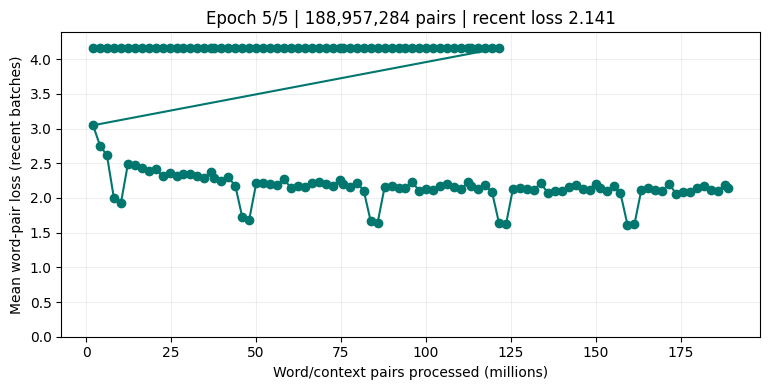

In [8]:
progress_fig, progress_ax = plt.subplots(figsize=(8, 4))
progress_line, = progress_ax.plot([], [], marker='o', color='#00776e')
progress_ax.set_xlabel('Word/context pairs processed (millions)')
progress_ax.set_ylabel('Mean word-pair loss (recent batches)')
progress_ax.set_title('Word2vec learning progress: waiting for the first update')
progress_ax.grid(alpha=0.2)
progress_fig.tight_layout()
plt.close(progress_fig)
progress_display = display(progress_fig, display_id=True)
learning_progress = []

def show_learning_progress(epoch, processed_pairs, mean_loss):
    learning_progress.append({'processed pairs': processed_pairs, 'recent loss': mean_loss})
    progress_line.set_data(
        [row['processed pairs'] / 1_000_000 for row in learning_progress],
        [row['recent loss'] for row in learning_progress])
    progress_ax.relim()
    progress_ax.autoscale_view()
    progress_ax.set_ylim(bottom=0)
    progress_ax.set_title(f'Epoch {epoch + 1}/{EPOCHS} | {processed_pairs:,} pairs | recent loss {mean_loss:.3f}')
    progress_display.update(progress_fig)

In [11]:
training_history = []
processed_pairs = 0
for epoch in range(EPOCHS):
    rng = np.random.default_rng(SEED + epoch)
    negative_rng = torch.Generator().manual_seed(SEED + epoch)
    total_loss, pair_count = 0., 0
    recent_loss, recent_pairs = 0., 0
    batch_count = 0
    for batch in pair_batches(training_ids, keep_probability, rng):
        pairs = torch.from_numpy(batch)
        negatives = torch.multinomial(
            noise_distribution, len(batch) * 5,
            replacement=True, generator=negative_rng,
        ).reshape(-1, 5)
        optimizer.zero_grad(set_to_none=True)
        loss = word2vec(pairs[:, 0], pairs[:, 1], negatives)
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite word2vec loss; stop and inspect training.')
        loss.backward()
        optimizer.step() # TODO: update the embedding tables
        batch_loss = loss.item() * len(batch)
        total_loss += batch_loss
        pair_count += len(batch)
        recent_loss += batch_loss
        recent_pairs += len(batch)
        processed_pairs += len(batch)
        batch_count += 1
        if batch_count % 500 == 0:
            show_learning_progress(epoch, processed_pairs, recent_loss / recent_pairs)
            recent_loss, recent_pairs = 0., 0
    if pair_count == 0:
        raise ValueError('No training word/context pairs survived subsampling.')
    if recent_pairs:
        show_learning_progress(epoch, processed_pairs, recent_loss / recent_pairs)
    training_history.append({'epoch': epoch + 1, 'positive pairs': pair_count,
                             'mean training loss': total_loss / pair_count})
    print(f'Epoch {epoch + 1}/{EPOCHS}: {pair_count:,} pairs; loss {total_loss / pair_count:.4f}', flush=True)
word2vec.eval()
learned_vectors = word2vec.input_embeddings.weight.detach().cpu().numpy().copy()
with torch.no_grad():
    final_pair_loss = word2vec(
        reference_pairs[:, 0], reference_pairs[:, 1], reference_negatives).item()
display(pd.DataFrame(training_history))
display(pd.Series({'before training': initial_pair_loss, 'after training': final_pair_loss},
                  name='Loss on the same fixed training pairs'))

Epoch 1/5: 37,795,226 pairs; loss 2.3981
Epoch 2/5: 37,791,794 pairs; loss 2.1571
Epoch 3/5: 37,787,754 pairs; loss 2.1059
Epoch 4/5: 37,793,136 pairs; loss 2.0822
Epoch 5/5: 37,789,374 pairs; loss 2.0690


,epoch,positive pairs,mean training loss
0,1,37795226,2.398058
1,2,37791794,2.157054
2,3,37787754,2.105899
3,4,37793136,2.082239
4,5,37789374,2.068970


before training    4.158883
after training     2.042518
Name: Loss on the same fixed training pairs, dtype: float64

## 6. Wähle die Wörter aus, die du untersuchen möchtest

Das Modell hat Vektoren für viele Wörter gelernt. **Bearbeite unten `chosen_words`**, um deine eigenen Beispiele auszuwählen. Gib die Wörter in Kleinbuchstaben ein, so wie wir es bei der Vorbereitung der Trainingstexte gemacht haben. Eine kurze Liste sorgt dafür, dass die Darstellung übersichtlich bleibt.

Probiere Wörter aus, von denen du erwartest, dass sie miteinander zusammenhängen, sowie einige Wörter, von denen du erwartest, dass sie unterschiedlich sind. Die bereitgestellte Liste ist nur ein Ausgangspunkt und keine vorgeschriebene Auswahl.

Wir entnehmen jeden Vektor direkt aus dem Modell, das wir gerade trainiert haben. Wir können nur Wörter darstellen, die das Modell gelernt hat. Der Code listet alle fehlenden Wörter auf und lässt sie weg. Für diese Übung werden mindestens drei bekannte Wörter benötigt.

Das trainierte Modell bleibt im Arbeitsspeicher. Es wird nicht automatisch gespeichert. Wenn du den Kernel neu startest, musst du das Modell deshalb erneut trainieren.

In [12]:
chosen_words = [
    'prize', 'reward', 'award', 'gift', 'bonus',
    'meeting', 'appointment', 'team', 'staff', 'office',
    'payment', 'invoice', 'bill', 'receipt', 'refund',
]
if len(set(chosen_words)) != len(chosen_words):
    raise ValueError('Choose each word only once.')
unknown_words = [word for word in chosen_words if word not in word_to_index]
if unknown_words:
    print('Not learned; left out of the map:', ', '.join(unknown_words))
map_words = [word for word in chosen_words if word in word_to_index]
if len(map_words) < 3:
    raise ValueError('Choose at least three words that the model learned.')
selected_vectors = learned_vectors[[word_to_index[word] for word in map_words]].astype(np.float64)
print(f'{len(map_words)} chosen words; {selected_vectors.shape[1]} learned numbers per word')
display(pd.Series(map_words, name='Words included in the map'))

15 chosen words; 100 learned numbers per word


0           prize
1          reward
2           award
3            gift
4           bonus
5         meeting
6     appointment
7            team
8           staff
9          office
10        payment
11        invoice
12           bill
13        receipt
14         refund
Name: Words included in the map, dtype: object

## 7. Die Ähnlichkeit anhand aller 100 Zahlen überprüfen

**Kosinus-Ähnlichkeit** vergleicht die Richtungen zweier Wortvektoren. Ein höherer Wert bedeutet, dass sie in ähnlichere Richtungen zeigen. Dies kann auf eine ähnliche Verwendung der Wörter hindeuten, beweist aber nicht, dass die Wörter dasselbe bedeuten.

Wir berechnen diese Werte anhand von **allen 100 Zahlen pro Wort**, bevor wir sie auf eine zweidimensionale Darstellung reduzieren. Später können wir überprüfen, ob die Darstellung einen ähnlichen Eindruck vermittelt.

Zuerst bringen wir jeden Vektor auf die Länge 1. Dies wird als **Normalisierung** bezeichnet. Mit Länge ist hier die numerische Grösse des Vektors gemeint, nicht die Anzahl seiner Einträge: Jedes Wort hat weiterhin 100 Zahlen. Dadurch wird verhindert, dass grössere Vektorlängen die Darstellung dominieren.

**Programmieraufgabe:** Teile jede Zeile von `selected_vectors` durch ihre Länge. Verwende dazu `word_lengths[:, None]`, damit NumPy für jede Zeile eine eigene Länge verwendet.

Die Tabelle vergleicht jedes ausgewählte Wort mit jedem anderen ausgewählten Wort. Jede Zeile und jede Spalte ist mit einem Wort beschriftet. Auf der Diagonale steht jeweils 1, weil dort ein Wort mit sich selbst verglichen wird. Betrachte die anderen Einträge, um unterschiedliche Wörter miteinander zu vergleichen.

In [13]:
word_lengths = np.linalg.norm(selected_vectors, axis=1)
if not np.isfinite(selected_vectors).all() or np.any(word_lengths == 0):
    raise ValueError('Cannot compare vectors with invalid numbers or zero length. Check the training results.')
unit_word_vectors = selected_vectors / word_lengths[:, None]  # TODO: divide each row by its own length
word_cosines = cosine_similarity(unit_word_vectors)
display(pd.DataFrame(word_cosines, index=map_words, columns=map_words).round(3))

,prize,reward,award,gift,bonus,meeting,appointment,team,staff,office,payment,invoice,bill,receipt,refund
prize,1.000,0.121,0.646,0.419,0.439,-0.003,0.180,0.237,0.188,0.131,0.338,0.155,-0.029,0.148,0.167
reward,0.121,1.000,0.153,0.264,0.352,0.153,0.005,0.075,0.258,0.091,0.191,0.011,0.053,-0.052,0.286
award,0.646,0.153,1.000,0.247,0.327,0.087,0.225,0.324,0.305,0.209,0.363,0.257,0.005,0.235,0.156
gift,0.419,0.264,0.247,1.000,0.541,0.052,0.132,0.070,-0.053,-0.012,0.195,-0.008,-0.111,0.069,0.162
bonus,0.439,0.352,0.327,0.541,1.000,0.086,0.091,0.169,0.065,-0.085,0.296,0.165,-0.097,0.186,0.190
meeting,-0.003,0.153,0.087,0.052,0.086,1.000,0.439,0.333,0.475,0.321,0.206,0.373,0.129,0.149,0.169
appointment,0.180,0.005,0.225,0.132,0.091,0.439,1.000,0.249,0.374,0.214,0.124,0.097,0.085,0.089,0.011
team,0.237,0.075,0.324,0.070,0.169,0.333,0.249,1.000,0.326,0.080,0.047,0.091,-0.100,0.091,-0.190
staff,0.188,0.258,0.305,-0.053,0.065,0.475,0.374,0.326,1.000,0.363,0.106,0.134,0.173,0.082,0.276
office,0.131,0.091,0.209,-0.012,-0.085,0.321,0.214,0.080,0.363,1.000,0.220,0.174,0.168,0.163,0.103


## 8. 100 Zahlen in eine Position auf einer Seite umwandeln

Wir können 100 Dimensionen nicht auf einer flachen Seite darstellen. Die **Hauptkomponentenanalyse (PCA)** findet zwei Richtungen, die möglichst viel von den Unterschieden zwischen diesen Wortvektoren sichtbar machen.

Das Ergebnis sind zwei Zahlen pro Wort: seine horizontale und seine vertikale Position. Dabei gehen einige Informationen verloren.

Der Titel zeigt an, wie viel der ursprünglichen Variation erhalten bleibt. **Variation** bedeutet hier, wie stark die ausgewählten Wortvektoren verteilt sind. Es ist **nicht der Prozentsatz der Bedeutung, die das Modell versteht**.

Wir verwenden alle von dir ausgewählten, bekannten Wörter, um diese Darstellung zu erstellen. Das unterscheidet sich von der Überprüfung eines Klassifikators: Wir beschreiben eine Gruppe von Wörtern und testen keine Vorhersagen anhand neuer E-Mails.

**Programmieraufgabe:** Verwende `word_map_pca.fit_transform(unit_word_vectors)`, um für jedes Wort die beiden Koordinaten für die Darstellung zu berechnen.

In [14]:
if np.allclose(unit_word_vectors, unit_word_vectors[0]):
    raise ValueError('These word vectors have no visible differences. Choose other words or check training.')
word_map_pca = PCA(n_components=2, svd_solver='full')
word_positions = word_map_pca.fit_transform(unit_word_vectors)  # TODO: calculate two coordinates per normalized word vector
retained_variation = word_map_pca.explained_variance_ratio_.sum()
print(f'Variation kept in the picture: {retained_variation:.1%}')

Variation kept in the picture: 32.1%


## 9. Zeichne deine Wortkarte

Führe den bereitgestellten Code zur Erstellung des Diagramms aus. Jeder Punkt basiert auf einem Wortvektor, den unser Modell gelernt hat und der mithilfe von PCA auf zwei Zahlen reduziert wurde.

Die Achsen haben keine Bezeichnungen wie „Spam“ oder „Geschäftlich“. Nahe beieinanderliegende Punkte sind ein Hinweis, den es sich lohnt zu untersuchen, aber kein Beweis dafür, dass die Wörter dieselbe Bedeutung haben.

Um eine andere Auswahl auszuprobieren, bearbeite `chosen_words` in Abschnitt 6 und führe die Abschnitte 6–9 erneut aus. **Du musst das Modell nicht erneut trainieren, nur um die Wörter in der Darstellung zu ändern.**

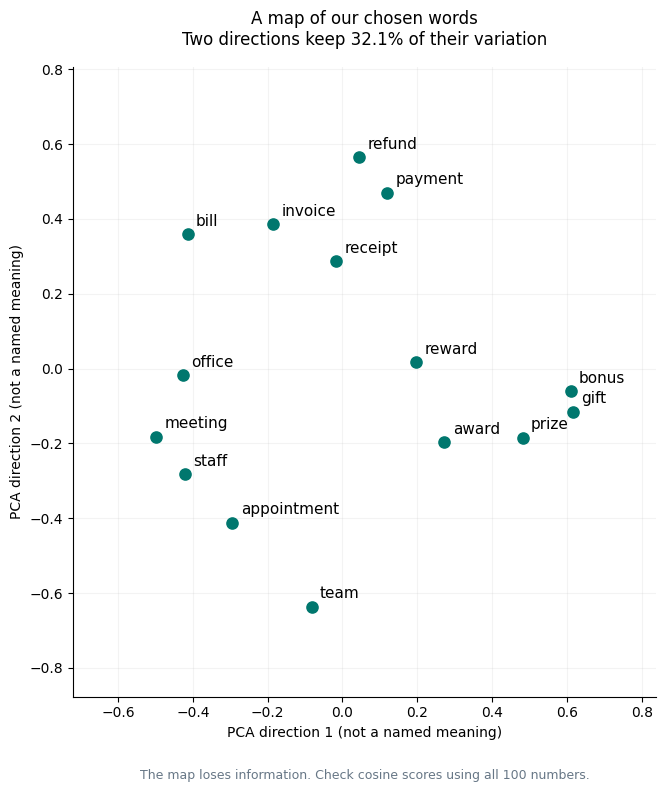

In [15]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.spines[['top', 'right']].set_visible(False)
ax.scatter(word_positions[:, 0], word_positions[:, 1],
           s=65, color='#00776e', zorder=3)
for word, (x, y) in zip(map_words, word_positions):
    ax.annotate(word, (x, y), xytext=(6, 6), textcoords='offset points', fontsize=11)
ax.set_xlabel('PCA direction 1 (not a named meaning)')
ax.set_ylabel('PCA direction 2 (not a named meaning)')
ax.set_title(f'A map of our chosen words\nTwo directions keep {retained_variation:.1%} of their variation', pad=16)
ax.grid(alpha=0.15)
ax.margins(0.2)
ax.set_aspect('equal', adjustable='box')
fig.text(0.5, 0.02, 'The map loses information. Check cosine scores using all 100 numbers.',
         ha='center', fontsize=9, color='#677786')
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 10. Was sagen uns die Ergebnisse?

1. Vergleiche den Loss (Verlustwert) vor und nach dem Training. Woraus hat das Modell gelernt? Warum beweist ein niedrigerer Loss nicht, dass Spam besser erkannt wird?
2. Wähle zwei Wortpaare aus deiner Ähnlichkeitstabelle. Welches Paar hat den höheren Kosinus-Ähnlichkeitswert? Vermittelt die Wortkarte denselben Eindruck?
3. Wie viel Variation bleibt in deiner Grafik erhalten? Warum sagt dieser Prozentsatz nichts darüber aus, wie gut das Modell Sprache versteht?
4. Würde eine überzeugende Wortkarte ausreichen, um einen Spam-Detektor für ein Unternehmen auszuwählen? Welchen Vergleich müsstest du dafür durchführen?

**Vorgeschlagene Antworten:**

1. Gib die Loss-Werte an, die du gemessen hast. Das Modell hat aus benachbarten Wörtern und zufällig ausgewählten Vergleichswörtern in den Trainings-E-Mails gelernt. Ein niedrigerer Loss bedeutet, dass es bei dieser Aufgabe besser geworden ist, aber nicht unbedingt bei der Spam-Erkennung.
2. Nenne deine ausgewählten Wortpaare und lies ihre Werte aus der Tabelle ab. Das Paar mit der höheren Kosinus-Ähnlichkeit hat im vollständigen 100-dimensionalen Vektorraum ähnlichere Richtungen. Die zweidimensionale Wortkarte kann einen anderen Eindruck vermitteln, weil bei der Reduktion Informationen verloren gehen. Die Kosinus-Ähnlichkeit ist keine Wahrscheinlichkeit dafür, dass zwei Wörter dasselbe bedeuten.
3. Gib den Prozentsatz an, der für deine eigene Wortauswahl angezeigt wird. Er misst, wie viel von der Streuung der ausgewählten Wortvektoren in zwei Dimensionen erhalten bleibt. Er misst weder das Sprachverständnis noch die Genauigkeit der Spam-Erkennung.
4. Nein. Vergleiche einen Klassifikator, der diese Wortvektoren verwendet, mit TF-IDF plus logistischer Regression. Verwende die Validierungs-E-Mails, um mögliche Schwellenwerte festzulegen, und die Test-E-Mails für den abschliessenden Vergleich. Überprüfe Precision, Recall, den Aufwand für die manuelle Überprüfung und die Kosten beider Fehlerarten.

**Bewertungsschema: 8 Punkte; Einführungsniveau.** Vergib zwei Punkte pro Frage:

- Gemessene Veränderung des Loss und eine korrekte Erklärung, woraus das Modell gelernt hat.
- Zwei tatsächliche Ähnlichkeitswerte von Wortpaaren und ein sorgfältiger Vergleich mit der Grafik.
- Der gemessene Prozentsatz und eine korrekte Erklärung, was er beschreibt.
- Ein Vergleich anhand von E-Mails, die nicht für das Training verwendet wurden, unter Berücksichtigung der geschäftlichen Kosten.

**Häufige Fehler:** Einen niedrigeren Loss mit einer höheren Genauigkeit der Spam-Erkennung gleichsetzen, die Kosinus-Ähnlichkeit als Wahrscheinlichkeit interpretieren, annehmen, dass die Achsen eine geschäftliche Bedeutung haben, oder die Wortkarte als exakte Darstellung aller 100 Dimensionen betrachten.

## Was du dir merken solltest

- Word2vec lernt aus benachbarten Wörtern, nicht aus Spam-Labels.
- Das Diagramm verwendet das Modell, das wir trainiert haben, und die Wörter, die wir ausgewählt haben. Es gibt keine separate Datei mit Wortvektoren.
- Ein Wort hat in diesem Modell einen einzigen festen Vektor. Das Modell kann *\*bank\** in einer E-Mail über Zahlungen keinen anderen Vektor zuweisen als in einer Beschreibung eines Flusses.
- Verwandte Wörter sind nicht immer austauschbar. Selbst Wörter mit gegensätzlicher Bedeutung können in ähnlichen Sätzen vorkommen.
- Bei der zweidimensionalen Darstellung gehen Informationen verloren. Überprüfe die Kosinus-Ähnlichkeitswerte anhand aller 100 Zahlen, bevor du behauptest, dass zwei Wörter nahe beieinanderliegen.

Eine neue Wortauswahl kann die PCA-Darstellung verändern. Unterschiedliche Softwareversionen können ausserdem die Achsen spiegeln, ähnlich wie bei einem Spiegelbild, ohne dass sich die Beziehungen zwischen den Wörtern verändern. Weder die Darstellung noch der Loss sagen uns, wie gut ein Spam-Klassifikator funktioniert.

Für einen vollständigen Vergleich von Klassifikatoren fahre mit der [Übung zur Stellenanzeigen-Kategorisierung]\(text_embeddings_exercise.ipynb) fort. Diese Übung lernt aus ihren eigenen Trainingsdaten. Verwende dafür nicht die Wortvektoren, die mit den E-Mails trainiert wurden.

**Deine Arbeit behalten:** Das trainierte Modell bleibt im Arbeitsspeicher des Notebooks. Es wird nicht automatisch gespeichert. Wenn du den Kernel neu startest, geht dieses Modell verloren, auch wenn gespeicherte Tabellen und Diagramme weiterhin sichtbar sind. Um das Training erneut vom gleichen Ausgangspunkt aus durchzuführen, führe das Notebook von Anfang an aus. Wenn du nur die Trainingsschleife erneut ausführst, wird das bestehende Modell weiter verändert.

Verwende die E-Mail-Daten nur im Rahmen der vereinbarten Berechtigungen des Kurses. Veröffentliche nicht die vollständige Wortliste des Modells.

**## Probiere es selbst aus**

**Eine andere Ansicht desselben Modells:** Verändere `chosen_words`, indem du bekannte Wörter hinzufügst oder entfernst. Führe die Abschnitte 6–9 erneut aus und gib den neuen Prozentsatz der erhaltenen Variation an. Warum kann sich die Darstellung verändern, obwohl sich die gelernten Wortvektoren nicht verändert haben? Probiere auch ein unbekanntes Wort aus und lies die Meldung darüber, ob das Modell dieses Wort gelernt hat.

**Optionaler nächster Schritt: Spam-Erkennung.** Berechne für jede E-Mail den Durchschnitt der bekannten Wortvektoren und trainiere anschliessend einen Klassifikator, wobei du ausschliesslich die Trainings-E-Mails und ihre Labels verwendest. Wähle mithilfe der Validierungs-E-Mails einen Schwellenwert für die Überprüfung aus. Vergleiche das Modell abschliessend mit TF-IDF plus logistischer Regression anhand der Test-E-Mails. Berücksichtige dabei auch die Kosten von Fehlalarmen und übersehenen Spam-E-Mails.

Wenn eine E-Mail keine Wörter enthält, die das Modell kennt, gib an, dass dafür eine andere Vorgehensweise erforderlich ist. Weise ihr nicht einfach unbemerkt einen Vektor zu, der nur aus Nullen besteht, und behandle die daraus resultierende Vorhersage nicht als aussagekräftig.

## Referenzen

**Vorlesungsfolien:** *Slides_MSC_Data_Science_Week_08_EN.pdf*, Seite 17, „Eine kleine Karte gelernter Wortbeziehungen“.

**Quellen der Lehrperson:** Das ursprüngliche Notebook aus Vorlesung 1 *word2vec_spam_detection.ipynb*, Abschnitte 7.1 und 9.4–9.6, sowie *word2vec_training.py*. Wir übernehmen daraus die Vorbereitung der Wortpaare und die Trainingsmethode. Der Code zum Einlesen der E-Mails wird auch im Material zu neuronalen Netzwerken verwendet. Weitere Informationen zu den Quellen und Nutzungsberechtigungen findest du in den [Hinweisen zu den Daten](../../../00_Data/nlp_data_readme.md).

**Offizielle Dokumentation, falls du den Code genauer untersuchen möchtest:** [PyTorch Embedding](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html), [SparseAdam](https://docs.pytorch.org/docs/stable/generated/torch.optim.SparseAdam.html), [scikit-learn PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) und [Kosinus-Ähnlichkeit](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html).

**Optionale weiterführende Literatur:** Mikolov et al. (2013), *Distributed Representations of Words and Phrases and their Compositionality*. https://arxiv.org/abs/1310.4546

### Angaben zur Abgabe

Gib deinen Namen, das Abgabedatum und eine kurze Beschreibung deiner Änderungen an.